In [1]:
import numpy as np
from matplotlib import pyplot as plt

## Gibb's Sampler Algorithm

In [2]:
def gibbs(N, n, a, b, c, d, xbar, ssquared):
    mat = np.zeros((N,2))
    mu = a/c
    tau = c
    mat[0, ] = (mu, tau)
    for i in range(1,N): 
        muprec = n*tau + d
        mumean = (d*c + n*tau*xbar)/muprec
        mu = np.random.normal(mumean, np.sqrt(1/muprec))
        
        taub = b + 0.5*((n - 1)*ssquared + n*pow((xbar - mu),2))
        tau = np.random.gamma(a + n/2, 1/taub)
        mat[i, ] = (mu, tau)
    return mat

In [3]:
postmat=gibbs(100000, 20, 1, 1, 3, 1/100, 30, 20)
x = range(1,100000)

### (i) marginal values of Mean vs iteration steps

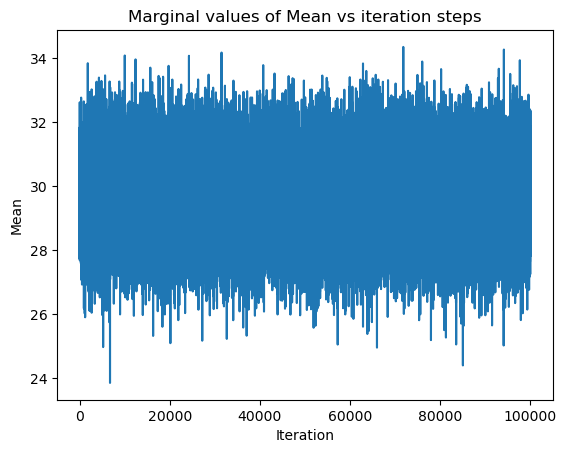

In [4]:
plt.plot(x,postmat[:,0][1:])
plt.title("Marginal values of Mean vs iteration steps")
plt.xlabel("Iteration")
plt.ylabel("Mean")
plt.show()

### (ii) marginal distribution for Mean

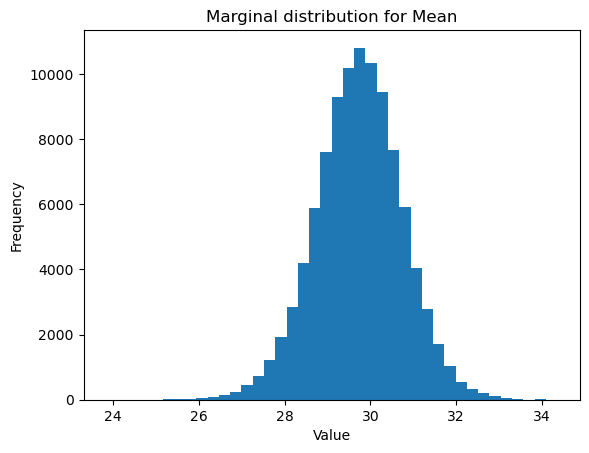

In [5]:
plt.hist(postmat[:,0][1:], bins = 40)
plt.title("Marginal distribution for Mean")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

### (iii) marginal values of Tau vs iteration steps

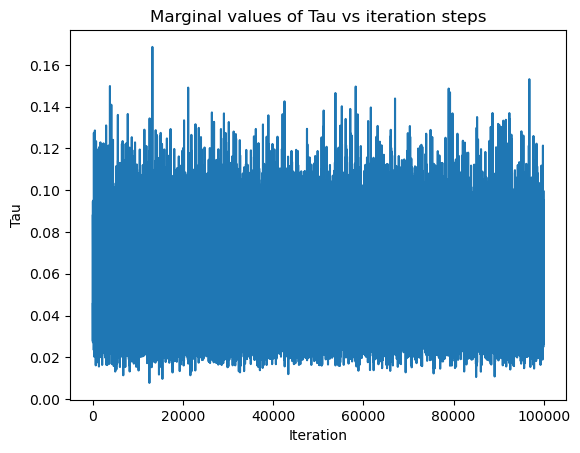

In [6]:
plt.plot(x,postmat[:,1][1:])
plt.title("Marginal values of Tau vs iteration steps")
plt.xlabel("Iteration")
plt.ylabel("Tau")
plt.show()

### (iv) marginal distribution for Tau

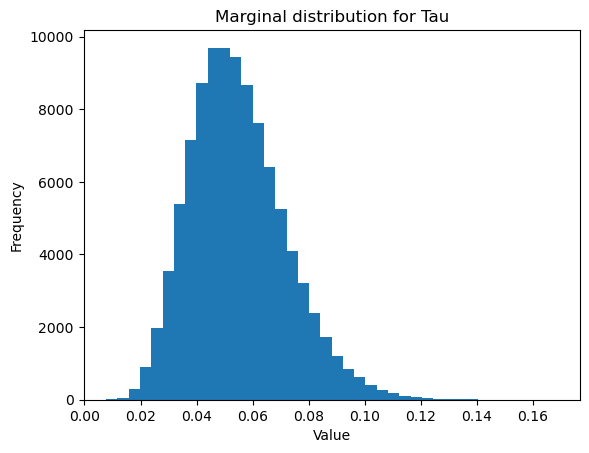

In [7]:
plt.hist(postmat[:,1][1:], bins = 40)
plt.title("Marginal distribution for Tau")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

### (v) the joint posterior distribution for Mean and Tau

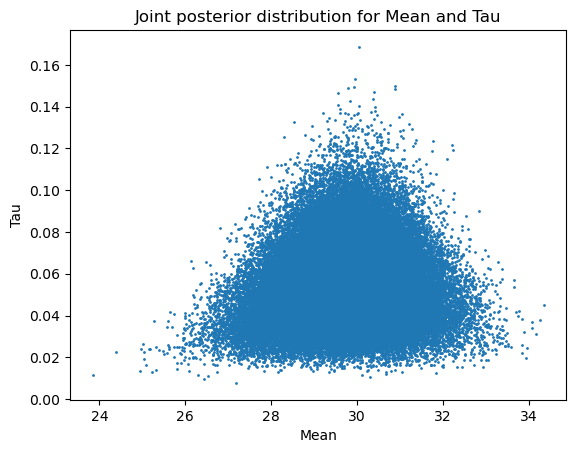

In [8]:
plt.scatter(postmat[:,0][1:],postmat[:,1][1:],s = 1)
plt.title("Joint posterior distribution for Mean and Tau")
plt.xlabel("Mean")
plt.ylabel("Tau")
plt.show()

### Compute and print the mean values for (vi) Mean and (vii) Tau

In [9]:
print(f'Mean value for Mean {np.mean(postmat[:,0][1:]):.3f}')
print(f'Mean value for Tau {np.mean(postmat[:,1][1:]):.3f}')

Mean value for Mean 29.733
Mean value for Tau 0.055
